# LogBERT against a rule-guided LLM on BGL: the full run on a GPU

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Amshu0-0/CA/blob/main/NLP/notebooks/train_on_gpu.ipynb)

CSCI 390 · Natural Language Processing · project of Amshu Wagle

This notebook runs the **whole experiment again on a GPU**, from the raw log to the final tables. Every number in it is produced
by the cells below; nothing is typed in.

| Part | What happens | Time on a free T4 GPU |
|---|---|---|
| 0 | check the GPU, connect Google Drive, get the code | 3 min |
| 1 | download BGL (4.7 million log lines) and prepare it: Drain templates, chronological 60/20/20 split, 5-minute windows | 20-40 min |
| 2 | **Approach A.** Train LogBERT with the full recipe (up to 50 epochs, early stopping), tune it on the validation period, test it | 20-60 min |
| 3 | **Approach B.** Qwen2.5-7B-Instruct writes the rules again from the training data and then labels the test templates four ways | 2-3 h |
| 4 | compare everything, error analysis, figures, tables, download | 10 min |

**How to run it**

1. *Runtime ▸ Change runtime type ▸ **T4 GPU*** (or a better GPU if you have Colab Pro), then Save.
2. *Runtime ▸ **Run all**.* Stay for the first minutes: Colab asks once for permission to use Google Drive. Click *Connect to Google Drive* and choose the account.
3. Keep this browser tab open until the last cell, and keep the computer awake. If the connection drops, open the notebook again and choose *Run all*: every stage that is finished is skipped, and the prepared data, the checkpoint and the language-model answers are kept in your Drive folder `CA-NLP-run`.
4. At the end the last cell downloads `nlp-gpu-results.zip`. Save this notebook with its outputs as well: *File ▸ Download ▸ Download .ipynb*.

**Switches** are in the next cell. `RERUN_LLM = False` skips part 3 and reuses the saved results of the reported run for approach B (about a minute instead of 2-3 hours).

In [ ]:
# ---- switches ----------------------------------------------------------------------------------------------------
SMOKE = False       # True: 2,000-line sample and a tiny model, only to check that every cell runs (about 2 minutes)
RERUN_LLM = True    # True : approach B is run again on this GPU with Qwen2.5-7B-Instruct (2-3 hours)
                    # False: the saved results of the reported approach B run are reused (about a minute)
USE_DRIVE = True    # keep the prepared data, the checkpoint and the language-model answers in your Google Drive
DRIVE_FOLDER = "CA-NLP-run"
# ------------------------------------------------------------------------------------------------------------------

import codecs
import os
import shutil
import subprocess
import sys
import time
from pathlib import Path

TIMES = {}   # seconds per stage; written to run_info.json at the end


def sh(command, tag=None, check=True, drop=()):
    """Run a shell command, show its output while it runs, and stop the notebook if the command fails."""
    print("$", command, flush=True)
    started = time.time()
    process = subprocess.Popen(command, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                               env={**os.environ, "PYTHONUNBUFFERED": "1"})
    decoder = codecs.getincrementaldecoder("utf-8")("replace")
    pending = ""
    try:
        while True:
            chunk = os.read(process.stdout.fileno(), 4096)
            if not chunk:
                break
            text = decoder.decode(chunk)
            if drop:      # line by line, so that unwanted lines can be left out
                pending += text
                *lines, pending = pending.split("\n")
                for line in lines:
                    if not any(word in line for word in drop):
                        print(line, flush=True)
            else:         # as it comes: progress bars rewrite their line with a carriage return
                sys.stdout.write(text)
                sys.stdout.flush()
        if pending and not any(word in pending for word in drop):
            print(pending, flush=True)
    except BaseException:  # the Stop button: do not leave the command running in the background
        process.terminate()
        try:
            process.wait(timeout=20)
        except subprocess.TimeoutExpired:
            process.kill()
        raise
    exit_code = process.wait()
    seconds = time.time() - started
    if tag:
        TIMES[tag] = TIMES.get(tag, 0) + seconds
    took = f"{seconds / 60:.1f} min" if seconds >= 90 else f"{seconds:.0f} s"
    print(f"[exit code {exit_code} after {took}]", flush=True)
    if exit_code != 0 and check:
        raise RuntimeError(f"The command failed (exit code {exit_code}): {command}")
    return exit_code

## 0. Set-up

In [ ]:
import torch

if SMOKE:
    GPU_NAME = "none (smoke test)"
    print("Smoke test: no GPU needed.")
else:
    if not torch.cuda.is_available():
        raise RuntimeError("No GPU found. Choose Runtime > Change runtime type > T4 GPU, then Runtime > Run all.")
    properties = torch.cuda.get_device_properties(0)
    GPU_NAME = properties.name
    print(f"GPU: {GPU_NAME}, {properties.total_memory / 2**30:.0f} GB   (PyTorch {torch.__version__}, CUDA {torch.version.cuda})")

GPU: Tesla T4, 15 GB   (PyTorch 2.14.1+cu130, CUDA 13.0)


In [ ]:
DRIVE = None
if SMOKE and os.environ.get("SMOKE_DRIVE"):      # the author's own test of the Drive steps, on a local folder
    DRIVE = Path(os.environ["SMOKE_DRIVE"])
elif USE_DRIVE and not SMOKE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE = Path("/content/drive/MyDrive") / DRIVE_FOLDER
    except Exception as error:                   # not on Colab, or the permission was refused
        print("Google Drive is not used:", error)
if DRIVE:
    DRIVE.mkdir(parents=True, exist_ok=True)
    print("Google Drive folder:", DRIVE)
else:
    print("Google Drive is not used: a disconnect would lose the work of this session.")

Mounted at /content/drive
Google Drive folder: /content/drive/MyDrive/CA-NLP-run


In [ ]:
ROOT = Path(os.environ.get("NLP_ROOT", "/content/CA/NLP"))     # NLP_ROOT is only used by the author's own test
if not ROOT.exists():
    sh("git clone -q --depth 1 -b main https://github.com/Amshu0-0/CA.git /content/CA")
os.chdir(ROOT)
if not SMOKE:
    packages = '"transformers>=4.45,<5" accelerate bitsandbytes openai' if RERUN_LLM else "openai"
    sh(f"pip install -q -e . matplotlib {packages}")
sys.path.insert(0, str(ROOT / "src"))
print("working folder:", Path.cwd())
sh("git log -1 --format='code version %h: %s (%cd)' --date=short || true", check=False)

$ git clone -q --depth 1 -b main https://github.com/Amshu0-0/CA.git /content/CA
[exit code 0 after 5 s]
$ pip install -q -e . matplotlib "transformers>=4.45,<5" accelerate bitsandbytes openai
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
pyiceberg 0.12.0 requires cachetools>=5.5, but you have cachetools 4.2.1 which is incompatible.
[exit code 0 after 25 s]
working folder: /content/CA/NLP
$ git log -1 --format='code version %h: %s (%cd)' --date=short || true
code version 8157ae2: Created using Colab (2026-11-14)
[exit cod

0

In [ ]:
import json
import logging
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True, "font.size": 9,
})

CODE = {"logbert": "A", "logbert_full": "A+", "llm_zero_shot": "B1", "llm_few_shot": "B2",
        "llm_rule_based": "B3", "keyword_rules": "B4"}
WHAT = {"A": "LogBERT", "A+": "LogBERT, full-coverage masking", "B1": "LLM zero-shot",
        "B2": "LLM few-shot", "B3": "LLM + rules", "B4": "keyword rules (no LLM)"}
BLUE, ORANGE, GREY = "#2f6db5", "#e07b24", "#8a8a85"
TICK = {"A": "LogBERT", "A+": "LogBERT\nfull coverage", "B1": "LLM\nzero-shot", "B2": "LLM\nfew-shot",
        "B3": "LLM\n+ rules", "B4": "keyword rules\n(no LLM)"}


def seconds_text(s):
    if s is None or pd.isna(s):
        return "-"
    if s < 1:
        return f"{s * 1000:.0f} ms"
    if s < 300:
        return f"{s:.0f} s"
    if s < 7200:
        return f"{s / 60:.0f} min"
    return f"{s / 3600:.1f} h"


def read_json(path, default=None):
    path = Path(path)
    return json.loads(path.read_text()) if path.exists() else default


def comparison_of(run):
    """The comparison table of a run folder (results/ layout), with the method codes A ... B4."""
    table = pd.read_csv(Path(run) / "comparison.csv")
    table["code"] = table["method"].map(CODE)
    table["what"] = table["code"].map(WHAT)
    return table


def plot_history(run, title="LogBERT training"):
    """Loss per epoch of a run folder that holds logbert/history.json."""
    history = pd.DataFrame(read_json(Path(run) / "logbert" / "history.json"))
    best = history.loc[history["dev_loss"].idxmin()]
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
    for ax, (name, key) in zip(axes, [("total loss", "loss"), ("masked key prediction (MLKP)", "mlkp"),
                                      ("hypersphere distance (VHM)", "vhm")]):
        ax.plot(history["epoch"], history[f"train_{key}"], marker="o", ms=3, color=BLUE, label="train")
        ax.plot(history["epoch"], history[f"dev_{key}"], marker="o", ms=3, color=ORANGE,
                label="dev (held-out normal windows)")
        ax.axvline(best["epoch"], color=GREY, ls=":")
        ax.set_title(name)
        ax.set_xlabel("epoch")
    axes[0].legend(frameon=False)
    fig.suptitle(title, y=1.02)
    plt.show()
    print(f"{len(history)} epochs; best dev loss {best['dev_loss']:.4f} at epoch {int(best['epoch'])} "
          f"(dotted line); {history['seconds'].mean():.0f} s per epoch, {history['seconds'].sum() / 60:.1f} min in total")
    return history


def logbert_summary(run):
    """Tuned settings and validation / test scores of A and A+ (reads results/<method>.json of a run folder)."""
    rows = []
    for method in ("logbert", "logbert_full"):
        found = read_json(Path(run) / f"{method}.json") or read_json(Path(run) / "results" / f"{method}.json")
        if not found:
            continue
        rows.append({"method": CODE[method], "g": found["settings"]["g"], "r": found["settings"]["r"],
                     "validation F1": found["validation"]["f1"], "test precision": found["test"]["precision"],
                     "test recall": found["test"]["recall"], "test F1": found["test"]["f1"],
                     "test false positives": found["test"]["fp"]})
    return pd.DataFrame(rows)

In [ ]:
GPU_CONFIG = '# =============================================================================\n# Full BGL on a GPU (Google Colab): LogBERT trained with the full recipe.\n#\n# The data, split, windows and the LogBERT architecture are those of\n# configs/bgl_cpu.yaml, the run that is reported in results/. What differs is\n# only the amount of LogBERT training, which is the one thing that the CPU run\n# had to cut down:\n#\n#                      bgl_cpu.yaml (results/)      bgl_gpu.yaml (results_gpu/)\n#   duplicate chunks   dropped (12,394 kept)        kept (every chunk, duplicates too)\n#   centre samples     4,000                        20,000\n#   epochs / patience  6 / 3                        up to 50 / 5 (early stopping)\n#   warm-up steps      200                          500\n#   device             cpu                          auto (the GPU)\n#\n# Approach B keeps the scope of the reported run (one induction round, test\n# period only); the notebook runs it again with Qwen2.5-7B-Instruct on the GPU.\n# =============================================================================\n\nextends: bgl_cpu.yaml\nname: bgl_gpu\n\npaths:\n  # Separate outputs so that nothing of the reported CPU run is overwritten.\n  output_dir: outputs/bgl_gpu\n\nlogbert:\n  dedupe_sequences: false\n  max_train_sequences: null\n  center_samples: 20000\n  epochs: 50\n  patience: 5\n  warmup_steps: 500\n  device: auto\n'

CONFIG = "configs/bgl_2k.yaml" if SMOKE else "configs/bgl_gpu.yaml"
if not SMOKE:
    Path(CONFIG).write_text(GPU_CONFIG)

from logad.config import load_config

cfg = load_config(CONFIG)
PROCESSED, OUT = Path(cfg.paths.processed_dir), Path(cfg.paths.output_dir)
LLM_CACHE = (DRIVE / "llm_cache") if DRIVE else Path("outputs/llm_cache_gpu")
FIGDIR, RES = Path("docs/figures_gpu"), Path("results_gpu")
lb = cfg.logbert
print(f"config {CONFIG}: LogBERT {lb.layers} layers, hidden {lb.hidden}, up to {lb.epochs} epochs (patience {lb.patience}), "
      f"duplicates {'dropped' if lb.dedupe_sequences else 'kept'}, centre from {lb.center_samples:,} sequences")
print("prepared data :", PROCESSED)
print("run outputs   :", OUT)

config configs/bgl_gpu.yaml: LogBERT 2 layers, hidden 256, up to 50 epochs (patience 5), duplicates kept, centre from 20,000 sequences
prepared data : data/processed/bgl
run outputs   : outputs/bgl_gpu


In [ ]:
def drive_push(*names):
    """Copy finished work to Google Drive (a no-op without Drive)."""
    if not DRIVE:
        return
    for name in names:
        source = {"processed": PROCESSED, "outputs": OUT}[name]
        if source.exists():
            shutil.copytree(source, DRIVE / name, dirs_exist_ok=True)
            print(f"saved to Drive: {name}")


def drive_pull():
    """A new virtual machine but the same Drive: bring back what an earlier session finished."""
    if not DRIVE:
        return
    for name, target in (("processed", PROCESSED), ("outputs", OUT)):
        if (DRIVE / name).exists() and not target.exists():
            shutil.copytree(DRIVE / name, target)
            print(f"restored from Drive: {target}")


drive_pull()

restored from Drive: data/processed/bgl
restored from Drive: outputs/bgl_gpu


## 1. The data

BGL is a log of the BlueGene/L supercomputer: 4,747,963 messages over seven months, each marked as normal or as an alert by the
machine itself. The preparation does four things:

1. **Drain** turns every message into a *template* (`ciod: Error loading <*>: invalid or missing program image`).
2. The log is cut **by time**: the first 60 % of the timeline is for training, the next 20 % for tuning (validation), the last 20 % for the test. Never at random, because a random split lets the model see the future.
3. **5-minute windows**, moved forward by 1 minute, are the unit that both approaches are scored on. A window is *anomalous* if it contains at least one alert message.
4. LogBERT sees only windows without alerts; the language model sees the text of templates.

In [ ]:
dataset = "bgl_2k" if SMOKE else "bgl"
if (PROCESSED / "windows.parquet").exists():
    print("The data is already prepared:", PROCESSED)
else:
    sh(f"python scripts/download_data.py --dataset {dataset}", tag="download")
    sh(f"python scripts/preprocess.py --config {CONFIG}", tag="preprocess")
    drive_push("processed")

The data is already prepared: data/processed/bgl


In [ ]:
windows = pd.read_parquet(PROCESSED / "windows.parquet")
facts = windows.groupby("split").agg(windows=("window_id", "count"), anomalous=("label", "sum"))
facts["anomalous %"] = (100 * facts["anomalous"] / facts["windows"]).round(1)
display(facts.loc[[s for s in ("train", "val", "test") if s in facts.index]])
if not SMOKE:
    test = windows[windows["split"] == "test"]
    same = len(test) == 5742 and int(test["label"].sum()) == 495
    print(f"test windows: {len(test):,}, anomalous: {int(test['label'].sum())}",
          "-> the same test windows as the reported run (5,742 / 495)" if same else "-> NOT the same as the reported run (5,742 / 495)")

,windows,anomalous,anomalous %
split,,,
train,21112,2083,9.9
val,10478,446,4.3
test,5742,495,8.6


test windows: 5,742, anomalous: 495 -> the same test windows as the reported run (5,742 / 495)


## 2. Approach A: LogBERT

LogBERT (Guo et al., 2021) is a small BERT. It reads a window as a sequence of template ids and is trained **only on normal windows**
to guess masked ids (*masked log-key prediction*) while pulling every window's summary vector towards a common centre
(*hypersphere loss*). A window is called anomalous when, among its masked keys, more than **r** are not within the model's top-**g**
guesses; **g** and **r** are tuned on the validation period. *A+* is our extension: masks cover every key once instead of a random half.

The recipe of this run (`configs/bgl_gpu.yaml`) is the full one: all training chunks, up to 50 epochs with early stopping on held-out
normal windows. The reported CPU run had to use 6 epochs on the 12,394 distinct chunks.

In [ ]:
model_file, history_file = OUT / "logbert" / "model.pt", OUT / "logbert" / "history.json"
if history_file.exists():
    print("LogBERT is already trained:", model_file)
elif model_file.exists():
    # An earlier training was stopped. The best checkpoint so far holds its own history, so use it instead of starting again.
    from logad.config import config_to_dict
    from logad.utils import save_json

    checkpoint = torch.load(model_file, map_location="cpu", weights_only=True)
    save_json(checkpoint["history"], history_file)
    save_json(config_to_dict(cfg), OUT / "logbert" / "config.json")
    print(f"An earlier training was stopped. Using its best checkpoint (epoch {len(checkpoint['history'])}).")
else:
    sh(f"python scripts/train_logbert.py --config {CONFIG}", tag="train")
    drive_push("outputs")

LogBERT is already trained: outputs/bgl_gpu/logbert/model.pt


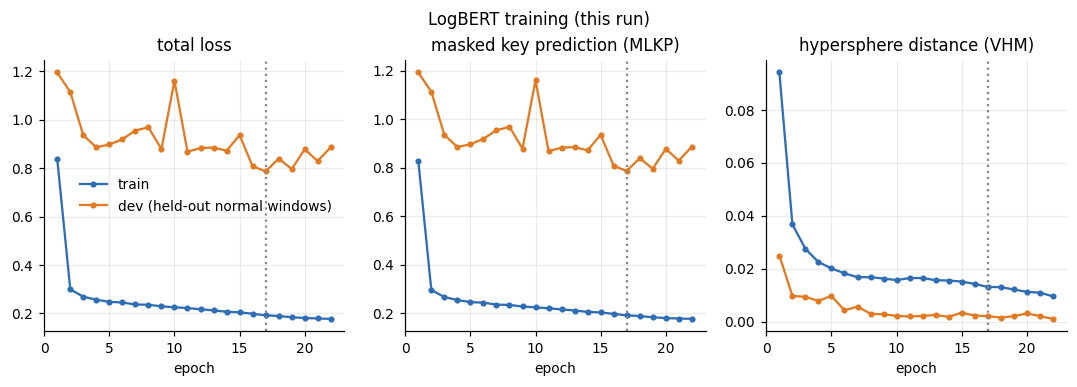

22 epochs; best dev loss 0.7866 at epoch 17 (dotted line); 116 s per epoch, 42.4 min in total


In [ ]:
history = plot_history(OUT, "LogBERT training (this run)")

In [ ]:
for flag, method in (("false", "logbert"), ("true", "logbert_full")):
    if (OUT / "results" / f"{method}.json").exists():
        print(method, "is already evaluated")
        continue
    sh(f"python scripts/evaluate_logbert.py --config {CONFIG} --set logbert.detection.full_coverage={flag}", tag="evaluate")
drive_push("outputs")
display(logbert_summary(OUT).style.format({"validation F1": "{:.3f}", "test precision": "{:.3f}", "test recall": "{:.3f}",
                                           "test F1": "{:.3f}", "test false positives": "{:,}"}).hide(axis="index"))

logbert is already evaluated
logbert_full is already evaluated
saved to Drive: outputs


method,g,r,validation F1,test precision,test recall,test F1,test false positives
A,12,3,0.573,0.175,0.921,0.294,"2,149"
A+,20,4,0.583,0.162,0.952,0.276,"2,445"


## 3. Approach B: rules written by a language model

Approach B (after LogRules, Huang et al., 2025) never trains on log sequences. A language model, **Qwen2.5-7B-Instruct**, is shown labeled *training*
templates and writes rules. Each rule is checked against all labeled training templates and **kept only if it is never wrong there**. The best 30 are used in four conditions,
each labeling the unique templates of the test period:

| | Condition | What the model gets |
|---|---|---|
| B1 | zero-shot | the template only |
| B2 | few-shot | the template and 8 labeled examples |
| B3 | rule-based | the template and the 30 rules |
| B4 | keyword rules | no model at all: the rules as plain string matching |

Nothing here is trained: the model is used as it is. What "learns" is the list of rules. With `RERUN_LLM = True` the model is loaded in 4-bit on this GPU, writes the rules
**again**, and answers every question **again** (its answers are stored one by one in the `llm_cache` folder of your Drive, so an interrupted run goes on where it stopped).

In [ ]:
LLM_MODEL = os.environ.get("SMOKE_LLM", "Qwen/Qwen2.5-7B-Instruct")
FOUR_BIT = "false" if SMOKE else "true"
LLM_ARGS = " ".join(
    [f"--set llm.cache_dir={LLM_CACHE}"]
    + [f"--set llm.{role}.backend=transformers --set llm.{role}.model={LLM_MODEL} --set llm.{role}.load_in_4bit={FOUR_BIT}"
       for role in ("generator", "classifier")]
)
CONDITION_FILE = {"zero_shot": "llm_zero_shot", "few_shot": "llm_few_shot", "rule_based": "llm_rule_based", "keyword": "keyword_rules"}


def reuse_reported_approach_b():
    """RERUN_LLM = False: the rules, the language-model decisions and the metrics of the reported run (results/)."""
    reported = Path("results")
    for sub in ("rules", "rule_guided"):
        shutil.copytree(reported / sub, OUT / sub, dirs_exist_ok=True)
    (OUT / "results").mkdir(parents=True, exist_ok=True)
    (OUT / "predictions").mkdir(parents=True, exist_ok=True)
    if SMOKE:        # the 2,000-line sample has its own windows: only the keyword rules can be applied to it
        sh(f"python scripts/run_rule_guided.py --config {CONFIG} --conditions keyword")
        return
    for method in CONDITION_FILE.values():
        shutil.copy(reported / f"{method}.json", OUT / "results" / f"{method}.json")
        shutil.copy(reported / "predictions" / f"{method}.parquet", OUT / "predictions" / f"{method}.parquet")
    # These results are valid only if this run has exactly the test windows of the reported run.
    new_windows = pd.read_parquet(PROCESSED / "windows.parquet")
    new_ids = set(new_windows.loc[new_windows["split"] == "test", "window_id"])
    old_ids = set(pd.read_parquet(reported / "predictions" / "logbert.parquet")["window_id"])
    if new_ids != old_ids:
        raise RuntimeError("This run does not have the test windows of the reported run, so its approach B results cannot be reused.")
    print("same test windows as the reported run: yes")
    # Second check: the keyword rules, recomputed here, must give the counts of the reported run.
    sh(f"python scripts/run_rule_guided.py --config {CONFIG} --conditions keyword")
    new, old = read_json(OUT / "results" / "keyword_rules.json")["test"], read_json(reported / "keyword_rules.json")["test"]
    print("keyword rules recomputed here give the counts of the reported run:", all(new[k] == old[k] for k in ("tp", "fp", "tn", "fn")))

In [ ]:
if not RERUN_LLM:
    reuse_reported_approach_b()
elif (OUT / "rules" / "rules.json").exists():
    print("The rules are already written:", OUT / "rules" / "rules.json")
else:
    # Loads the model (a download of about 15 GB the first time, then a few minutes), then 42 prompts of about a minute each.
    sh(f"python scripts/induce_rules.py --config {CONFIG} {LLM_ARGS}", tag="induce_rules")
    drive_push("outputs")

The rules are already written: outputs/bgl_gpu/rules/rules.json


In [ ]:
rules = read_json(OUT / "rules" / "rules.json", [])
info = read_json(OUT / "rules" / "induction_summary.json", {})
if rules:
    print(f"The language model proposed {info.get('n_candidates', '?')} rules in {info.get('n_batches', '?')} prompts; "
          f"{info.get('n_kept', len(rules))} were kept because they are never wrong on the labeled training templates. "
          f"The top 30 are used. Generator: {info.get('generator', '?')}")
    names = {0: "normal", 1: "abnormal", "normal": "normal", "abnormal": "abnormal"}
    overview = pd.DataFrame([{
        "rank": i + 1, "label": names.get(r["label"], r["label"]), "rule (the model's words)": r["text"],
        "keywords": ", ".join(r["keywords"][:4]) + (" ..." if len(r["keywords"]) > 4 else ""),
        "training templates (all correct)": r["correct"], "training messages": r["message_coverage"],
    } for i, r in enumerate(rules[:12])])
    display(Markdown("**The 12 highest-ranked rules**"))
    display(overview.style.format({"training messages": "{:,}"}).hide(axis="index"))
else:
    print("no rules in this run")

The language model proposed 130 rules in 42 prompts; 54 were kept because they are never wrong on the labeled training templates. The top 30 are used. Generator: transformers:Qwen/Qwen2.5-7B-Instruct


**The 12 highest-ranked rules**

rank,label,rule (the model's words),keywords,training templates (all correct),training messages
1,normal,Indicates a normal operational message,fee,25,33
2,normal,System status alerts,"alert, clock mode, temperature mask, temperature limit error latch ...",7,"16,196"
3,abnormal,"Signals a kernel panic, a serious system error.","kernel, panic",6,"21,054"
4,abnormal,System log entries related to abnormal termination,"exited abnormally, terminated for reason",6,"17,205"
5,abnormal,Signals a critical system error.,"rts panic!, rts: kernel terminated",5,"21,042"
6,abnormal,Indicates termination of kernel due to unexpected reasons.,"kernel, terminated, reason",5,"17,199"
7,abnormal,Indicates termination of the kernel.,"kernel, terminated",5,"17,199"
8,abnormal,Kernel terminations and panics are severe errors.,"kernel terminated for reason, kernel panic",5,"17,199"
9,abnormal,Reflects a failure in the communication or network infrastructure.,"no ethernet link, socket to, socket closed",4,"25,882"
10,abnormal,Signals a kernel termination due to an error.,rts: kernel terminated,4,"17,187"


In [ ]:
if RERUN_LLM:
    todo = [c for c, method in CONDITION_FILE.items() if not (OUT / "results" / f"{method}.json").exists()]
    if todo:
        # One program run for all conditions, so the model is loaded once. Answers are stored as they arrive: if Colab
        # disconnects, run this cell again and the finished answers are taken from the cache.
        sh(f"python scripts/run_rule_guided.py --config {CONFIG} --conditions {' '.join(todo)} {LLM_ARGS}", tag="classify")
        drive_push("outputs")
    else:
        print("All four conditions are already done.")
else:
    print("RERUN_LLM is False: approach B was taken from the reported run (see above).")

$ python scripts/run_rule_guided.py --config configs/bgl_gpu.yaml --conditions zero_shot few_shot rule_based keyword --set llm.cache_dir=/content/drive/MyDrive/CA-NLP-run/llm_cache --set llm.generator.backend=transformers --set llm.generator.model=Qwen/Qwen2.5-7B-Instruct --set llm.generator.load_in_4bit=true --set llm.classifier.backend=transformers --set llm.classifier.model=Qwen/Qwen2.5-7B-Instruct --set llm.classifier.load_in_4bit=true

== llm_zero_shot ==
13:55:40 | INFO    | logad.llm.client | Loading Qwen/Qwen2.5-7B-Instruct (this can take a few minutes)...
I0000 00:00:1794664543.174437    3188 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794664546.346779    3188 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
`t

## 4. Everything side by side

`compare.py` scores every method on the same test windows with the same code, and `analyze.py` writes the error analysis.
`make_figures.py` draws the figures from the run's own files. Then the run is collected in the folder `results_gpu/`, laid out like `results/`.

In [ ]:
sh(f"python scripts/compare.py --config {CONFIG}", tag="compare")
sh(f"python scripts/analyze.py --config {CONFIG}", tag="analyze")
sh(f"python scripts/make_figures.py --config {CONFIG} --out {FIGDIR}", tag="figures", check=False, drop=("findfont",))
drive_push("outputs")

$ python scripts/compare.py --config configs/bgl_gpu.yaml
Test set: 5,742 windows, 495 anomalous (8.6%).

| Method | Precision | Recall | F1 | FP | FN | Msg-level F1 | Inference (s) |
|---|---:|---:|---:|---:|---:|---:|---:|
| A  LogBERT | 0.175 | 0.921 | 0.294 | 2,149 | 39 | - | 4.9 |
| A+ LogBERT, full-coverage masking (ext.) | 0.162 | 0.952 | 0.276 | 2,445 | 24 | - | 10.1 |
| B1 LLM zero-shot | 0.105 | 1.000 | 0.190 | 4,219 | 0 | 0.283 | 918.3 |
| B2 LLM few-shot (case-based) | 0.439 | 0.939 | 0.598 | 595 | 30 | 0.512 | 968.3 |
| B3 LLM rule-based | 0.416 | 0.992 | 0.586 | 690 | 4 | 0.504 | 1561.8 |
| B4 Keyword rules (no LLM) | 0.889 | 0.954 | 0.920 | 59 | 23 | 0.708 | 0.0 |

Saved to outputs/bgl_gpu/results/comparison.md
[exit code 0 after 1 s]
$ python scripts/analyze.py --config configs/bgl_gpu.yaml
Wrote outputs/bgl_gpu/analysis/analysis.md
[exit code 0 after 42 s]
$ python scripts/make_figures.py --config configs/bgl_gpu.yaml --out docs/figures_gpu
Data and drift
  wrote docs/

In [ ]:
def put(source, pattern, subfolder=""):
    target = RES / subfolder
    target.mkdir(parents=True, exist_ok=True)
    for file in sorted(Path(source).glob(pattern)):
        if file.is_file():
            shutil.copy(file, target / file.name)


if RES.exists():
    shutil.rmtree(RES)
put(OUT / "results", "*")                                    # metrics of every method, comparison.csv and .md
put(OUT / "predictions", "*.parquet", "predictions")
put(OUT / "rules", "*", "rules")
put(OUT / "rule_guided", "*_decisions.csv", "rule_guided")
put(OUT / "analysis", "*", "analysis")
for name in ("model.pt", "history.json", "*_tuning_grid.csv"):
    put(OUT / "logbert", name, "logbert")
put(FIGDIR, "*", "figures")
size = sum(f.stat().st_size for f in RES.rglob("*") if f.is_file()) / 2**20
print(f"collected {len(list(RES.rglob('*')))} entries ({size:.1f} MB) in {RES}/")

collected 67 entries (8.1 MB) in results_gpu/


## 5. The results of this run

Everything below is read from `results_gpu/`. The first table is the result; the second puts it next to the **reported run** (LogBERT trained for 6 epochs on a CPU,
approach B run with a llama.cpp copy of the same model).

In [ ]:
# What to show: RUN is a folder in the layout of results/ (what `make results` writes).
RUN, BASE, FIG = RES, Path("results"), RES / "figures"
RUN_LABEL, BASE_LABEL = "new run", "reported run"
table = comparison_of(RUN)
n_windows, n_alerts = int(table["support"].iloc[0]), int(table.iloc[0]["tp"] + table.iloc[0]["fn"])
print(f"Test period: {n_windows:,} windows, {n_alerts} of them anomalous ({100 * n_alerts / n_windows:.1f}%)")
best = table.loc[table["f1"].idxmax()]
print(f"Highest F1 on the test windows: {best['code']} {best['what']} ({best['f1']:.3f})")
shown = table[["code", "what", "precision", "recall", "f1", "tp", "fp", "fn", "inference_seconds"]].copy()
shown["inference"] = shown["inference_seconds"].map(seconds_text)
shown = shown.drop(columns="inference_seconds").rename(columns={"code": "", "what": "method"})
display(shown.style.format({"precision": "{:.3f}", "recall": "{:.3f}", "f1": "{:.3f}", "tp": "{:,}",
                            "fp": "{:,}", "fn": "{:,}"}).hide(axis="index")
        .set_properties(subset=["method"], **{"text-align": "left"})
        .background_gradient(subset=["f1"], cmap="Blues", vmin=0, vmax=1))

Test period: 5,742 windows, 495 of them anomalous (8.6%)
Highest F1 on the test windows: B4 keyword rules (no LLM) (0.920)


,method,precision,recall,f1,tp,fp,fn,inference
A,LogBERT,0.175,0.921,0.294,456,"2,149",39,5 s
A+,"LogBERT, full-coverage masking",0.162,0.952,0.276,471,"2,445",24,10 s
B1,LLM zero-shot,0.105,1.000,0.190,495,"4,219",0,15 min
B2,LLM few-shot,0.439,0.939,0.598,465,595,30,16 min
B3,LLM + rules,0.416,0.992,0.586,491,690,4,26 min
B4,keyword rules (no LLM),0.889,0.954,0.920,472,59,23,19 ms


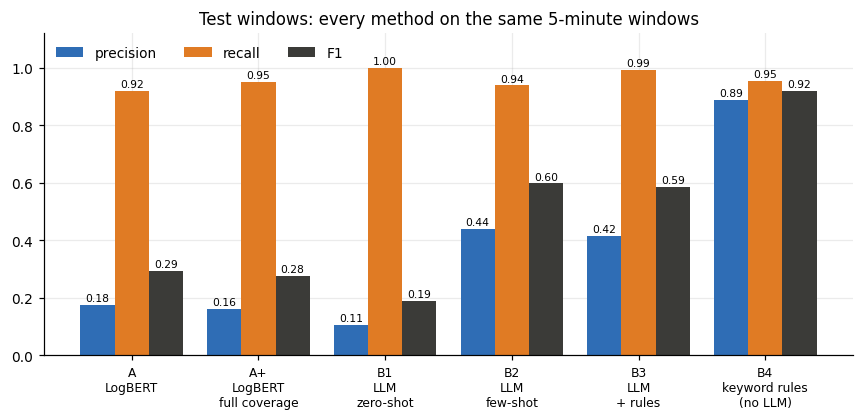

In [ ]:
fig, ax = plt.subplots(figsize=(9.5, 3.8))
x = np.arange(len(table))
for i, (column, label, color) in enumerate([("precision", "precision", BLUE), ("recall", "recall", ORANGE), ("f1", "F1", "#3b3b38")]):
    bars = ax.bar(x + (i - 1) * 0.27, table[column], 0.27, label=label, color=color)
    ax.bar_label(bars, labels=[f"{v:.2f}" for v in table[column]], fontsize=7, padding=1)
ax.set_xticks(x, [f"{c}\n{TICK[c]}" for c in table["code"]], fontsize=8)
ax.set_ylim(0, 1.12)
ax.set_title("Test windows: every method on the same 5-minute windows")
ax.legend(frameon=False, ncol=3, loc="upper left")
plt.show()

In [ ]:
if BASE is not None and (BASE / "comparison.csv").exists():
    old, new = comparison_of(BASE).set_index("code"), comparison_of(RUN).set_index("code")
    side = pd.DataFrame({
        "method": new["what"],
        f"F1 {BASE_LABEL}": old["f1"], f"F1 {RUN_LABEL}": new["f1"],
        f"precision {BASE_LABEL}": old["precision"], f"precision {RUN_LABEL}": new["precision"],
        f"recall {BASE_LABEL}": old["recall"], f"recall {RUN_LABEL}": new["recall"],
        f"false positives {BASE_LABEL}": old["fp"], f"false positives {RUN_LABEL}": new["fp"],
    })
    side["F1 change"] = side[f"F1 {RUN_LABEL}"] - side[f"F1 {BASE_LABEL}"]
    display(Markdown(f"**{RUN_LABEL} against the {BASE_LABEL}**"))
    float_columns = [c for c in side.columns if c.startswith(("F1", "precision", "recall"))]
    display(side.style.format({**{c: "{:.3f}" for c in float_columns}, "F1 change": "{:+.3f}",
                               f"false positives {BASE_LABEL}": "{:,}", f"false positives {RUN_LABEL}": "{:,}"}))

**new run against the reported run**

,method,F1 reported run,F1 new run,precision reported run,precision new run,recall reported run,recall new run,false positives reported run,false positives new run,F1 change
code,,,,,,,,,,
A,LogBERT,0.293,0.294,0.174,0.175,0.921,0.921,"2,159","2,149",+0.001
A+,"LogBERT, full-coverage masking",0.305,0.276,0.184,0.162,0.897,0.952,"1,975","2,445",-0.029
B1,LLM zero-shot,0.194,0.190,0.108,0.105,1.000,1.000,"4,103","4,219",-0.004
B2,LLM few-shot,0.481,0.598,0.323,0.439,0.941,0.939,976,595,+0.117
B3,LLM + rules,0.644,0.586,0.489,0.416,0.943,0.992,488,690,-0.058
B4,keyword rules (no LLM),0.956,0.920,1.000,0.889,0.915,0.954,0,59,-0.036


### How to read the tables

- **Precision** is the share of flagged windows that really contain an alert; **recall** is the share of anomalous windows that are flagged. With 8.6 % anomalous windows,
  a detector that flags too much has a low precision however high its recall is.
- **False positives (FP)** are normal windows that were flagged, which is what an operator would have to look at for nothing.
- A method that flags everything has recall 1.00 and precision 0.086: look at the **F1** column to compare methods.

**Approach A: settings chosen on the validation period, and how they do on the test period**

method,g,r,validation F1,test precision,test recall,test F1,test false positives
A,12,3,0.573,0.175,0.921,0.294,"2,149"
A+,20,4,0.583,0.162,0.952,0.276,"2,445"


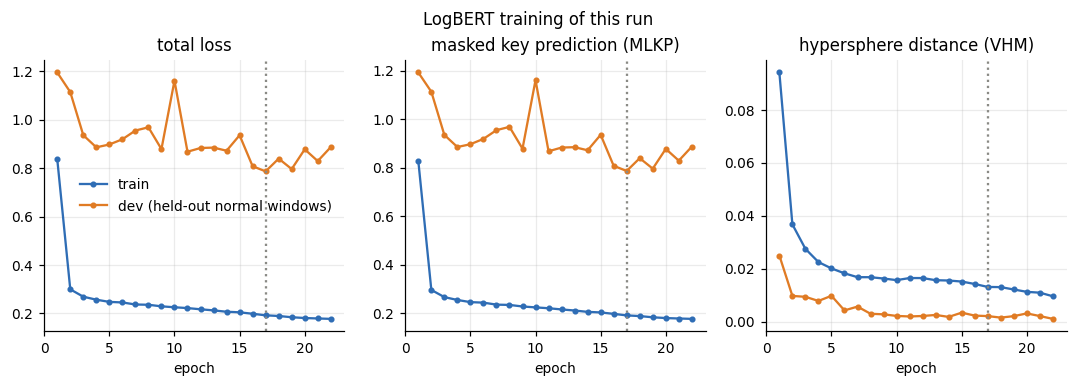

22 epochs; best dev loss 0.7866 at epoch 17 (dotted line); 116 s per epoch, 42.4 min in total
reported run: 6 epochs, 60 min, best dev loss 1.0241
new run: 22 epochs, 42 min, best dev loss 0.7866


In [ ]:
display(Markdown("**Approach A: settings chosen on the validation period, and how they do on the test period**"))
summary = logbert_summary(RUN)
display(summary.style.format({"validation F1": "{:.3f}", "test precision": "{:.3f}", "test recall": "{:.3f}",
                              "test F1": "{:.3f}", "test false positives": "{:,}"}).hide(axis="index"))
history = plot_history(RUN, "LogBERT training of this run")
if BASE is not None and (BASE / "logbert" / "history.json").exists():
    old = pd.DataFrame(read_json(BASE / "logbert" / "history.json"))
    print(f"{BASE_LABEL}: {len(old)} epochs, {old['seconds'].sum() / 60:.0f} min, best dev loss {old['dev_loss'].min():.4f}")
    print(f"{RUN_LABEL}: {len(history)} epochs, {history['seconds'].sum() / 60:.0f} min, best dev loss {history['dev_loss'].min():.4f}")

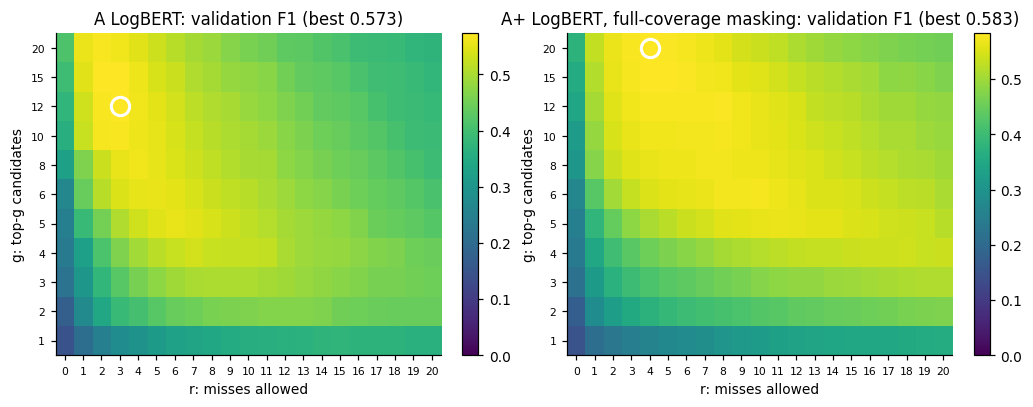

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, method in zip(axes, ["logbert", "logbert_full"]):
    path = RUN / "logbert" / f"{method}_tuning_grid.csv"
    if not path.exists():
        ax.set_visible(False)
        continue
    grid = pd.read_csv(path)
    pivot = grid.pivot(index="g", columns="r", values="f1")
    image = ax.imshow(pivot.values, aspect="auto", origin="lower", cmap="viridis", vmin=0)
    ax.set_xticks(range(len(pivot.columns)), pivot.columns, fontsize=7)
    ax.set_yticks(range(len(pivot.index)), pivot.index, fontsize=7)
    best = grid.loc[grid["f1"].idxmax()]
    ax.plot(list(pivot.columns).index(best["r"]), list(pivot.index).index(best["g"]), "o", mfc="none", mec="white", ms=12, mew=2)
    ax.set_xlabel("r: misses allowed")
    ax.set_ylabel("g: top-g candidates")
    ax.set_title(f"{CODE[method]} {WHAT[CODE[method]]}: validation F1 (best {best['f1']:.3f})")
    ax.grid(False)
    fig.colorbar(image, ax=ax, fraction=0.046)
plt.show()

In [ ]:
rules = read_json(RUN / "rules" / "rules.json", [])
info = read_json(RUN / "rules" / "induction_summary.json", {})
if rules:
    print(f"The language model proposed {info.get('n_candidates', '?')} rules in {info.get('n_batches', '?')} prompts; "
          f"{info.get('n_kept', len(rules))} were kept because they are never wrong on the labeled training templates. "
          f"The top 30 are used. Generator: {info.get('generator', '?')}")
    names = {0: "normal", 1: "abnormal", "normal": "normal", "abnormal": "abnormal"}
    overview = pd.DataFrame([{
        "rank": i + 1, "label": names.get(r["label"], r["label"]), "rule (the model's words)": r["text"],
        "keywords": ", ".join(r["keywords"][:4]) + (" ..." if len(r["keywords"]) > 4 else ""),
        "training templates (all correct)": r["correct"], "training messages": r["message_coverage"],
    } for i, r in enumerate(rules[:12])])
    display(Markdown("**The 12 highest-ranked rules**"))
    display(overview.style.format({"training messages": "{:,}"}).hide(axis="index"))
else:
    print("no rules in this run")

The language model proposed 130 rules in 42 prompts; 54 were kept because they are never wrong on the labeled training templates. The top 30 are used. Generator: transformers:Qwen/Qwen2.5-7B-Instruct


**The 12 highest-ranked rules**

rank,label,rule (the model's words),keywords,training templates (all correct),training messages
1,normal,Indicates a normal operational message,fee,25,33
2,normal,System status alerts,"alert, clock mode, temperature mask, temperature limit error latch ...",7,"16,196"
3,abnormal,"Signals a kernel panic, a serious system error.","kernel, panic",6,"21,054"
4,abnormal,System log entries related to abnormal termination,"exited abnormally, terminated for reason",6,"17,205"
5,abnormal,Signals a critical system error.,"rts panic!, rts: kernel terminated",5,"21,042"
6,abnormal,Indicates termination of kernel due to unexpected reasons.,"kernel, terminated, reason",5,"17,199"
7,abnormal,Indicates termination of the kernel.,"kernel, terminated",5,"17,199"
8,abnormal,Kernel terminations and panics are severe errors.,"kernel terminated for reason, kernel panic",5,"17,199"
9,abnormal,Reflects a failure in the communication or network infrastructure.,"no ethernet link, socket to, socket closed",4,"25,882"
10,abnormal,Signals a kernel termination due to an error.,rts: kernel terminated,4,"17,187"


In [ ]:
rows = []
for method in ["llm_zero_shot", "llm_few_shot", "llm_rule_based", "keyword_rules"]:
    found = read_json(RUN / f"{method}.json")
    if not found:
        continue
    rows.append({"": CODE[method], "condition": WHAT[CODE[method]], "classifier": found.get("classifier"),
                 "templates classified": found.get("n_templates_classified"),
                 "unparsed answers": found.get("n_unparsed_answers"),
                 "message-level F1": (found.get("test_message_level") or {}).get("f1"),
                 "time to classify": seconds_text(found.get("inference_seconds"))})
if rows:
    display(pd.DataFrame(rows).style.format({"message-level F1": "{:.3f}"}, na_rep="-").hide(axis="index"))

,condition,classifier,templates classified,unparsed answers,message-level F1,time to classify
B1,LLM zero-shot,transformers:Qwen/Qwen2.5-7B-Instruct,472,0,0.283,15 min
B2,LLM few-shot,transformers:Qwen/Qwen2.5-7B-Instruct,472,0,0.512,16 min
B3,LLM + rules,transformers:Qwen/Qwen2.5-7B-Instruct,472,0,0.504,26 min
B4,keyword rules (no LLM),keyword matching,472,0,0.708,19 ms


### Error analysis

In [ ]:
figure_data = read_json(FIG / "figure_data.json", {})
unseen = figure_data.get("unseen_templates", {}).get("percent_by_split")
panels = figure_data.get("window_scores", {}).get("panels")
misses = figure_data.get("key_misses", {}).get("groups")


def percent(value):
    return "-" if value is None else f"{value:.2f}%"


if unseen:
    print(f"Messages whose template never occurred in training: validation period {unseen['val']:.1f}%, test period {unseen['test']:.1f}%")
if panels:
    print("\nLogBERT (A) on the test windows, by kind of window:")
    for name, values in panels.items():
        print(f"  {name:<58} {values.get('windows', 0):>6,} windows, {percent(values.get('percent_flagged')):>8} flagged")
if misses:
    print("\nLogBERT (A): share of masked keys that are not in the top-g predictions:")
    for name, values in misses.items():
        print(f"  {name:<12} {values.get('keys', 0):>9,} keys, {percent(values.get('percent_missed')):>8} missed")

Messages whose template never occurred in training: validation period 8.9%, test period 79.6%

LogBERT (A) on the test windows, by kind of window:
  Normal windows, every template seen in training             1,514 windows,    0.26% flagged
  Normal windows with a template never seen in training       3,733 windows,   57.46% flagged
  Anomalous windows (contain an alert)                          495 windows,   92.12% flagged

LogBERT (A): share of masked keys that are not in the top-g predictions:
  known_normal    92,859 keys,    2.11% missed
  known_alert        821 keys,    0.61% missed
  new_normal     360,557 keys,  100.00% missed
  new_alert       28,094 keys,  100.00% missed


In [ ]:
analysis = RUN / "analysis"
rename = {**{k: v for k, v in CODE.items()}}

purity = read_json(analysis / "template_purity.json")
if purity:
    print(f"Templates: {purity['n_templates']} in the test period; {purity['n_mixed_templates']} are mixed (normal and alert messages). "
          f"A perfect template-level labeler would reach window F1 {purity['oracle_window_level']['f1']:.3f}, so labelling templates is enough for this data.")

for title, name in [("Templates whose label changes between training and test", "label_drift.csv"),
                    ("Templates that hold both normal and alert messages", "mixed_templates.csv")]:
    if (analysis / name).exists():
        display(Markdown(f"**{title}**"))
        display(pd.read_csv(analysis / name).style.hide(axis="index"))

if (analysis / "per_category_recall.csv").exists():
    recall = pd.read_csv(analysis / "per_category_recall.csv").rename(columns=rename)
    display(Markdown("**Recall per alert category (window level): which kinds of alerts each method misses**"))
    method_columns = [c for c in recall.columns if c in WHAT]
    display(recall.style.format({c: "{:.2f}" for c in method_columns}).hide(axis="index")
            .background_gradient(subset=method_columns, cmap="Blues", vmin=0, vmax=1))

if (analysis / "method_agreement.csv").exists():
    agree = pd.read_csv(analysis / "method_agreement.csv")
    agree["method_a"], agree["method_b"] = agree["method_a"].map(CODE), agree["method_b"].map(CODE)
    display(Markdown("**Do two methods catch the same anomalous windows? (and do they make the same false alarms?)**"))
    display(agree.style.hide(axis="index"))

if (analysis / "combinations.csv").exists():
    combos = pd.read_csv(analysis / "combinations.csv")
    combos["method_a"], combos["method_b"] = combos["method_a"].map(CODE), combos["method_b"].map(CODE)
    display(Markdown("**Combining an approach A method with an approach B method (either one flags / both flag)**"))
    display(combos.style.format({"precision": "{:.3f}", "recall": "{:.3f}", "f1": "{:.3f}", "fp": "{:,}"}).hide(axis="index"))

faith = read_json(analysis / "rule_faithfulness.json")
if faith:
    print("Does the rule-based LLM (B3) apply the rules it cites?")
    print(f"  {faith['answers_citing_a_rule']} of {faith['templates']} answers cite a rule, but the cited rule's keyword occurs in the template "
          f"in only {faith['cited_rule_occurs_in_template']} of them;")
    print(f"  {faith['abnormal_answers']} templates are called abnormal, only {faith['abnormal_answers_backed_by_an_occurring_rule']} of them backed by a rule that really occurs in the template.")

Templates: 472 in the test period; 3 are mixed (normal and alert messages). A perfect template-level labeler would reach window F1 0.996, so labelling templates is enough for this data.


**Templates whose label changes between training and test**

template_id,template,n_train,n_train_anomalous,n_test,n_test_anomalous
65,ciod: LOGIN <*> failed: <*> <*>,472,0,816,816
34,data <*> <*>,84360,63488,79,1


**Templates that hold both normal and alert messages**

template_id,template,n_test,n_test_anomalous,alert_tags
20,machine <*> <*>,127,4,KERNMC
34,data <*> <*>,79,1,KERNSTOR
86,DDR <*> <*> register: <*> <*>,52,26,KERNMC


**Recall per alert category (window level): which kinds of alerts each method misses**

... (2 outputs left out)

method_a,method_b,both_caught,only_a,only_b,neither,shared_false_positives
A,A+,456,0,15,24,2126
A,B1,456,0,39,0,1819
A,B2,448,8,17,22,141
A,B3,454,2,37,2,236
A,B4,443,13,29,10,59
A+,B1,471,0,24,0,2047
A+,B2,460,11,5,19,158
A+,B3,469,2,22,2,253
A+,B4,454,17,18,6,59
B1,B2,465,30,0,0,595


**Combining an approach A method with an approach B method (either one flags / both flag)**

method_a,method_b,combination,precision,recall,f1,fp
A,B1,either (OR),0.098,1.000,0.179,"4,549"
A,B1,both (AND),0.200,0.921,0.329,"1,819"
A,B2,either (OR),0.154,0.956,0.265,"2,603"
A,B2,both (AND),0.761,0.905,0.827,141
A,B3,either (OR),0.159,0.996,0.275,"2,603"
A,B3,both (AND),0.658,0.917,0.766,236
A,B4,either (OR),0.184,0.980,0.310,"2,149"
A,B4,both (AND),0.882,0.895,0.889,59
A+,B1,either (OR),0.097,1.000,0.177,"4,617"
A+,B1,both (AND),0.187,0.952,0.313,"2,047"


Does the rule-based LLM (B3) apply the rules it cites?
  391 of 472 answers cite a rule, but the cited rule's keyword occurs in the template in only 13 of them;
  47 templates are called abnormal, only 9 of them backed by a rule that really occurs in the template.


### The figures of this run

**Figure 1. BGL over time: normal and alert messages per week**

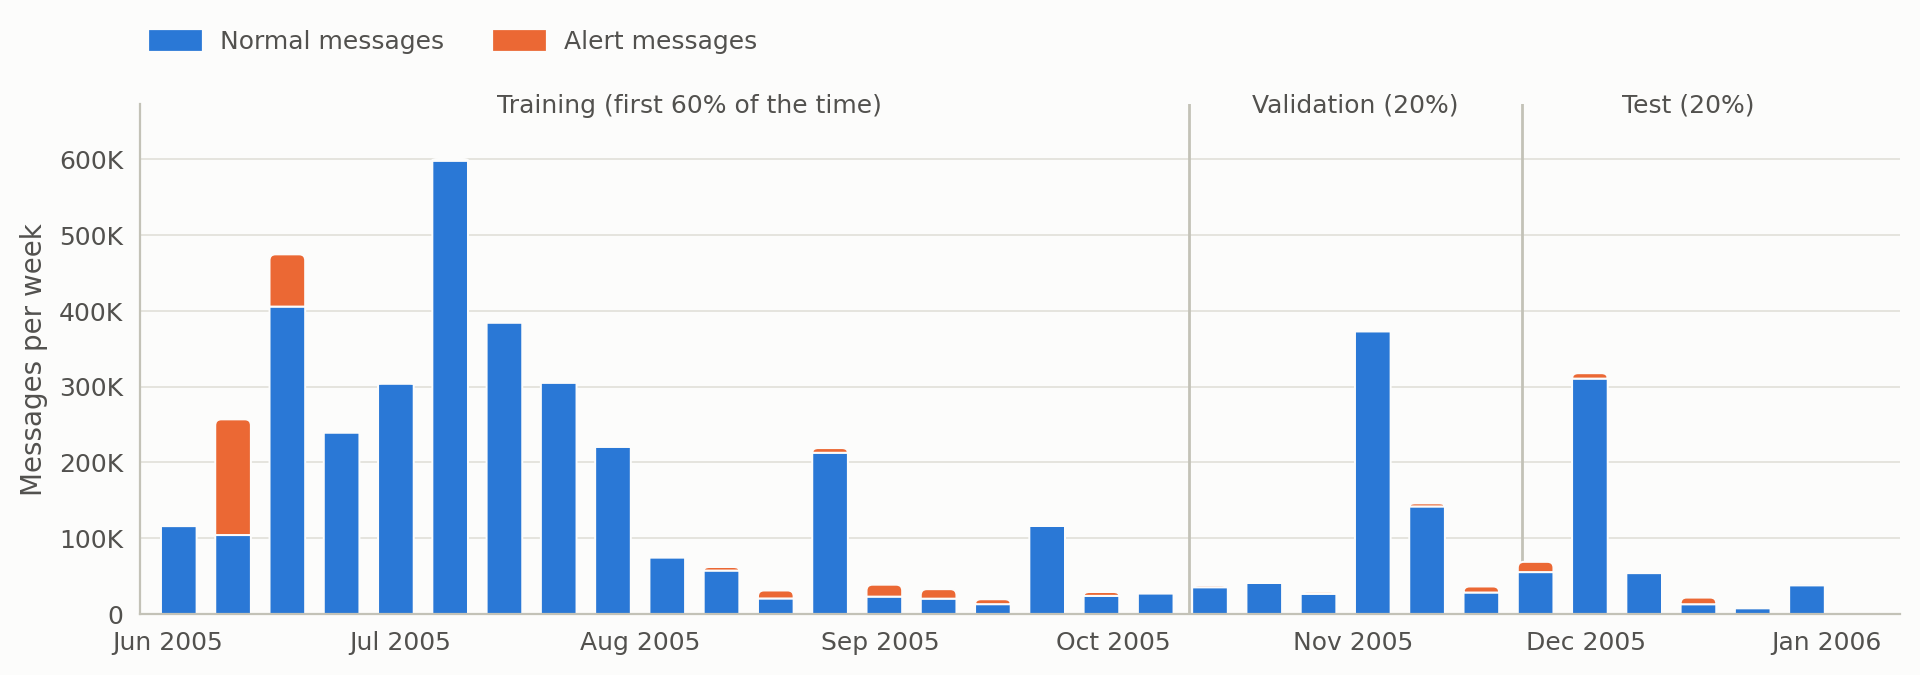

**Figure 2. Share of messages whose template never occurred in the training period**

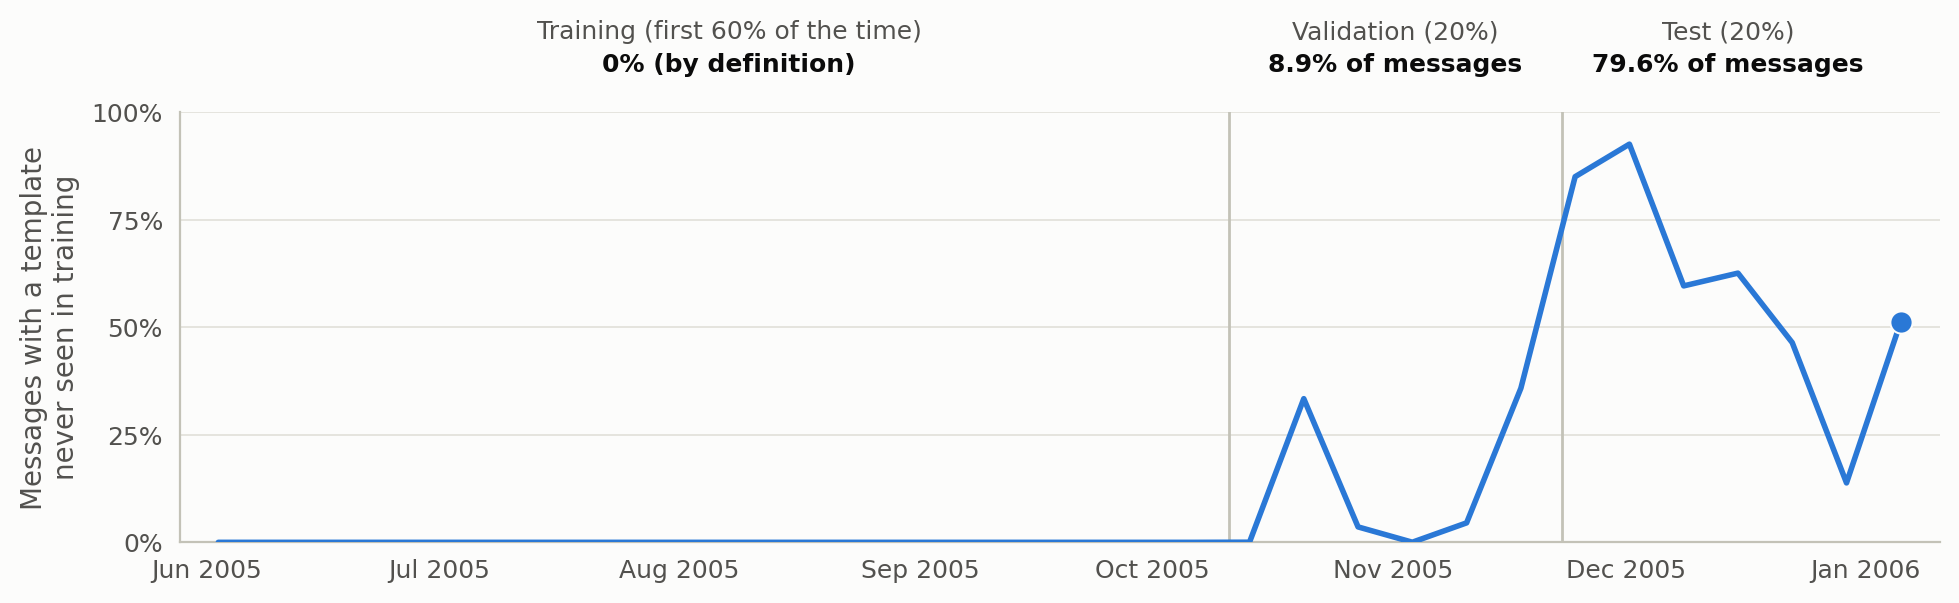

**Figure 3. LogBERT: loss per epoch**

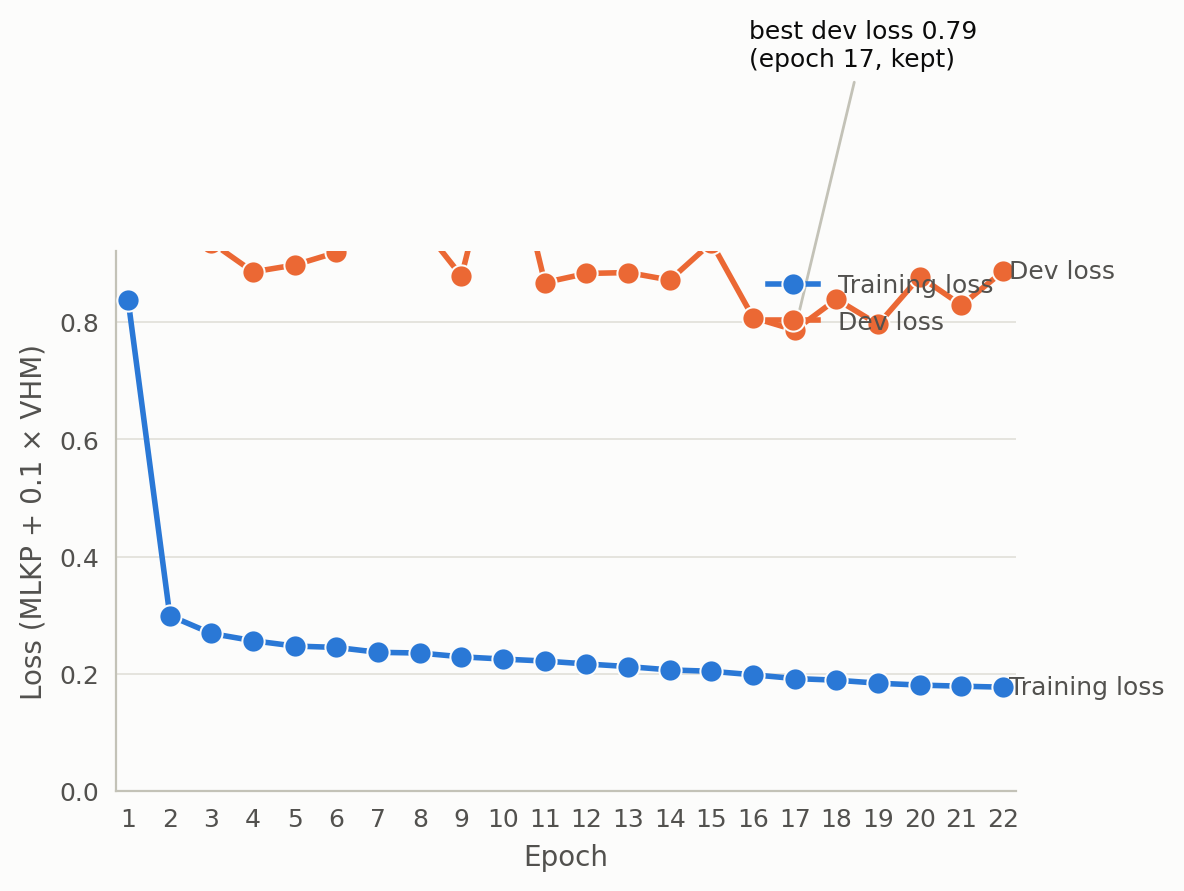

**Figure 4. LogBERT: validation F1 for every (g, r) setting**

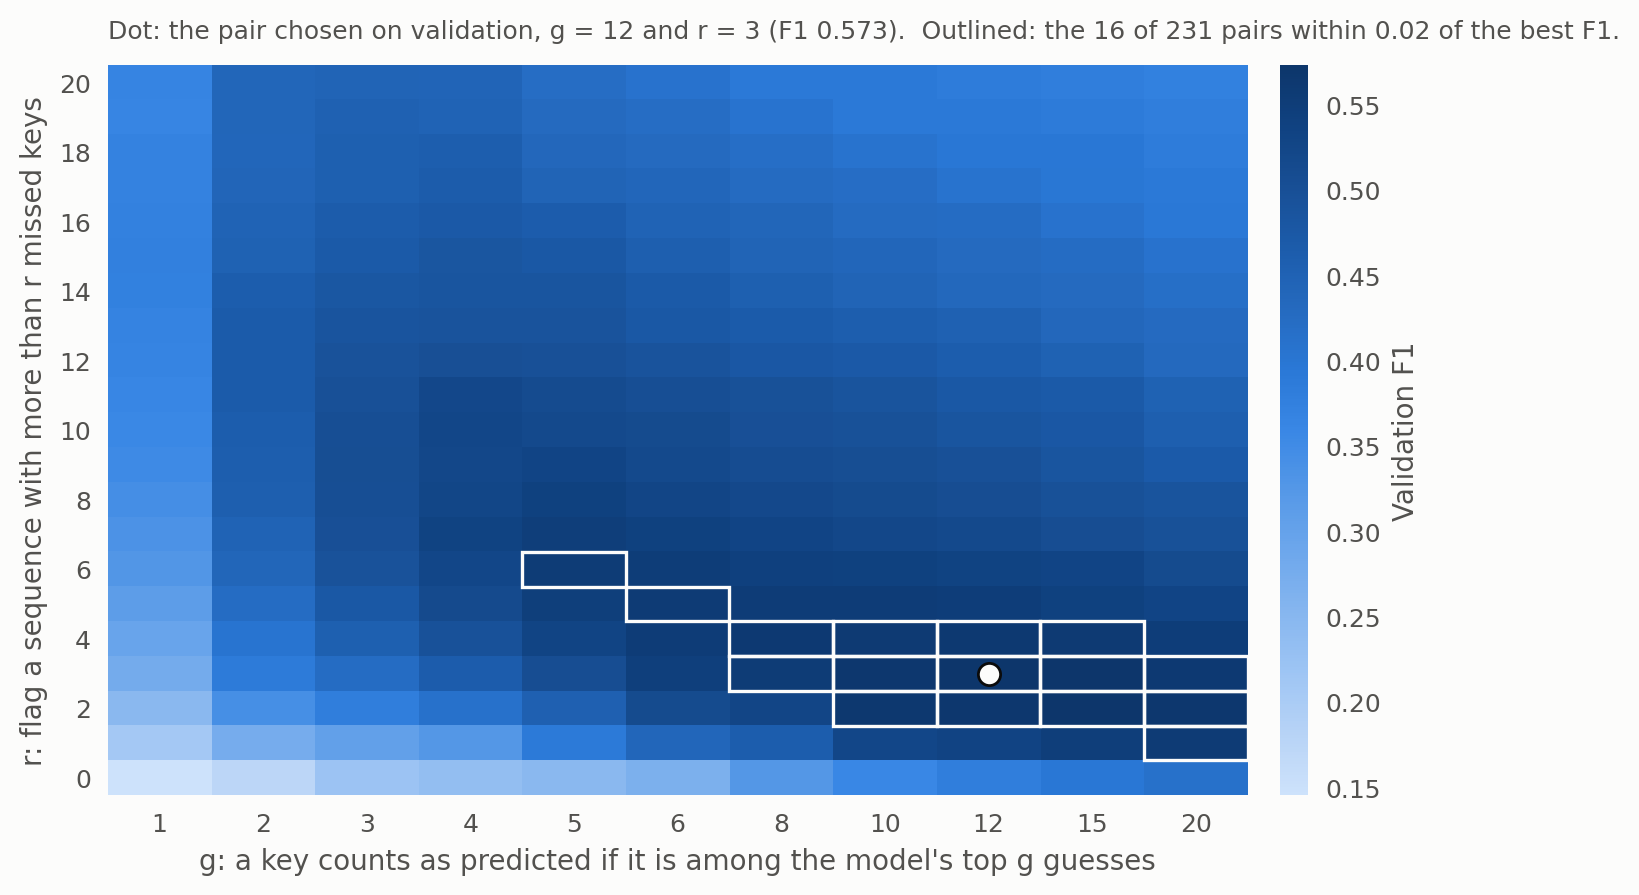

**Figure 5. LogBERT: which log keys it cannot predict (known templates against never-seen ones)**

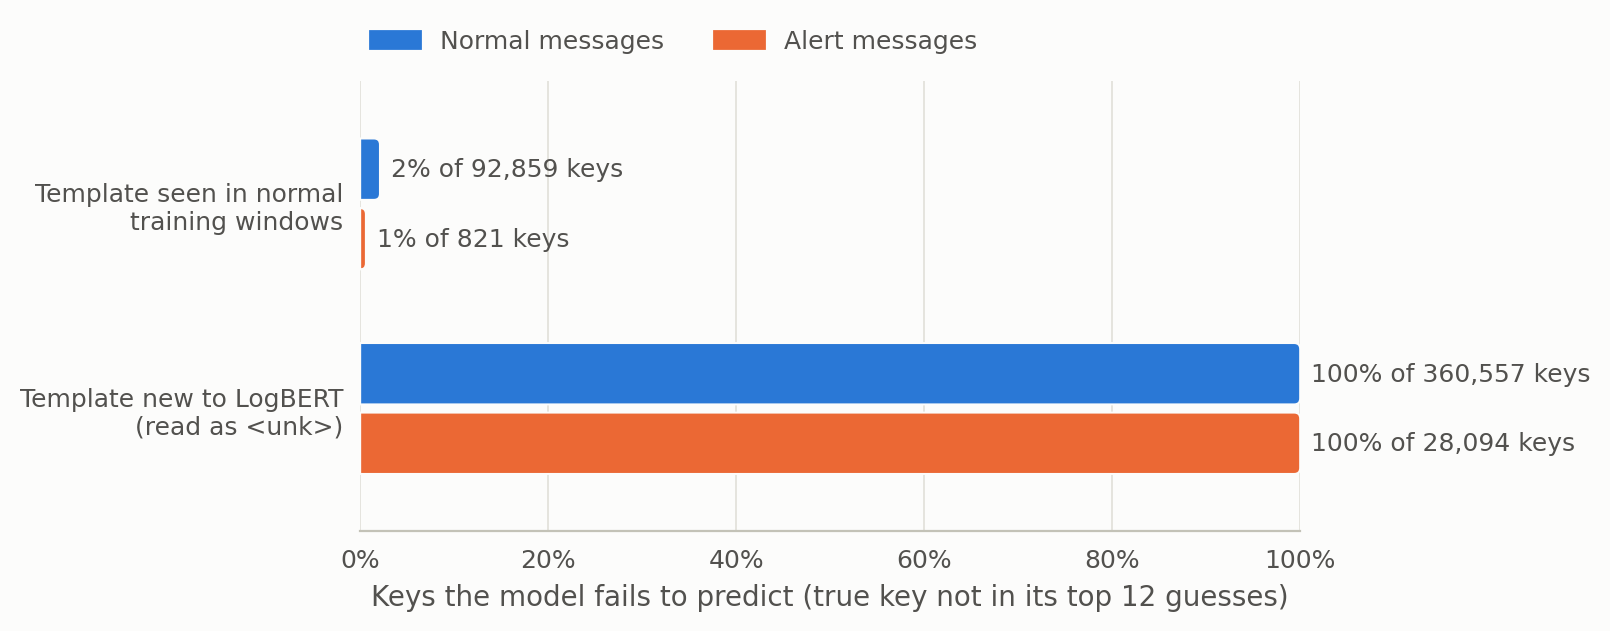

**Figure 6. LogBERT: window scores of normal, unseen-template and anomalous windows**

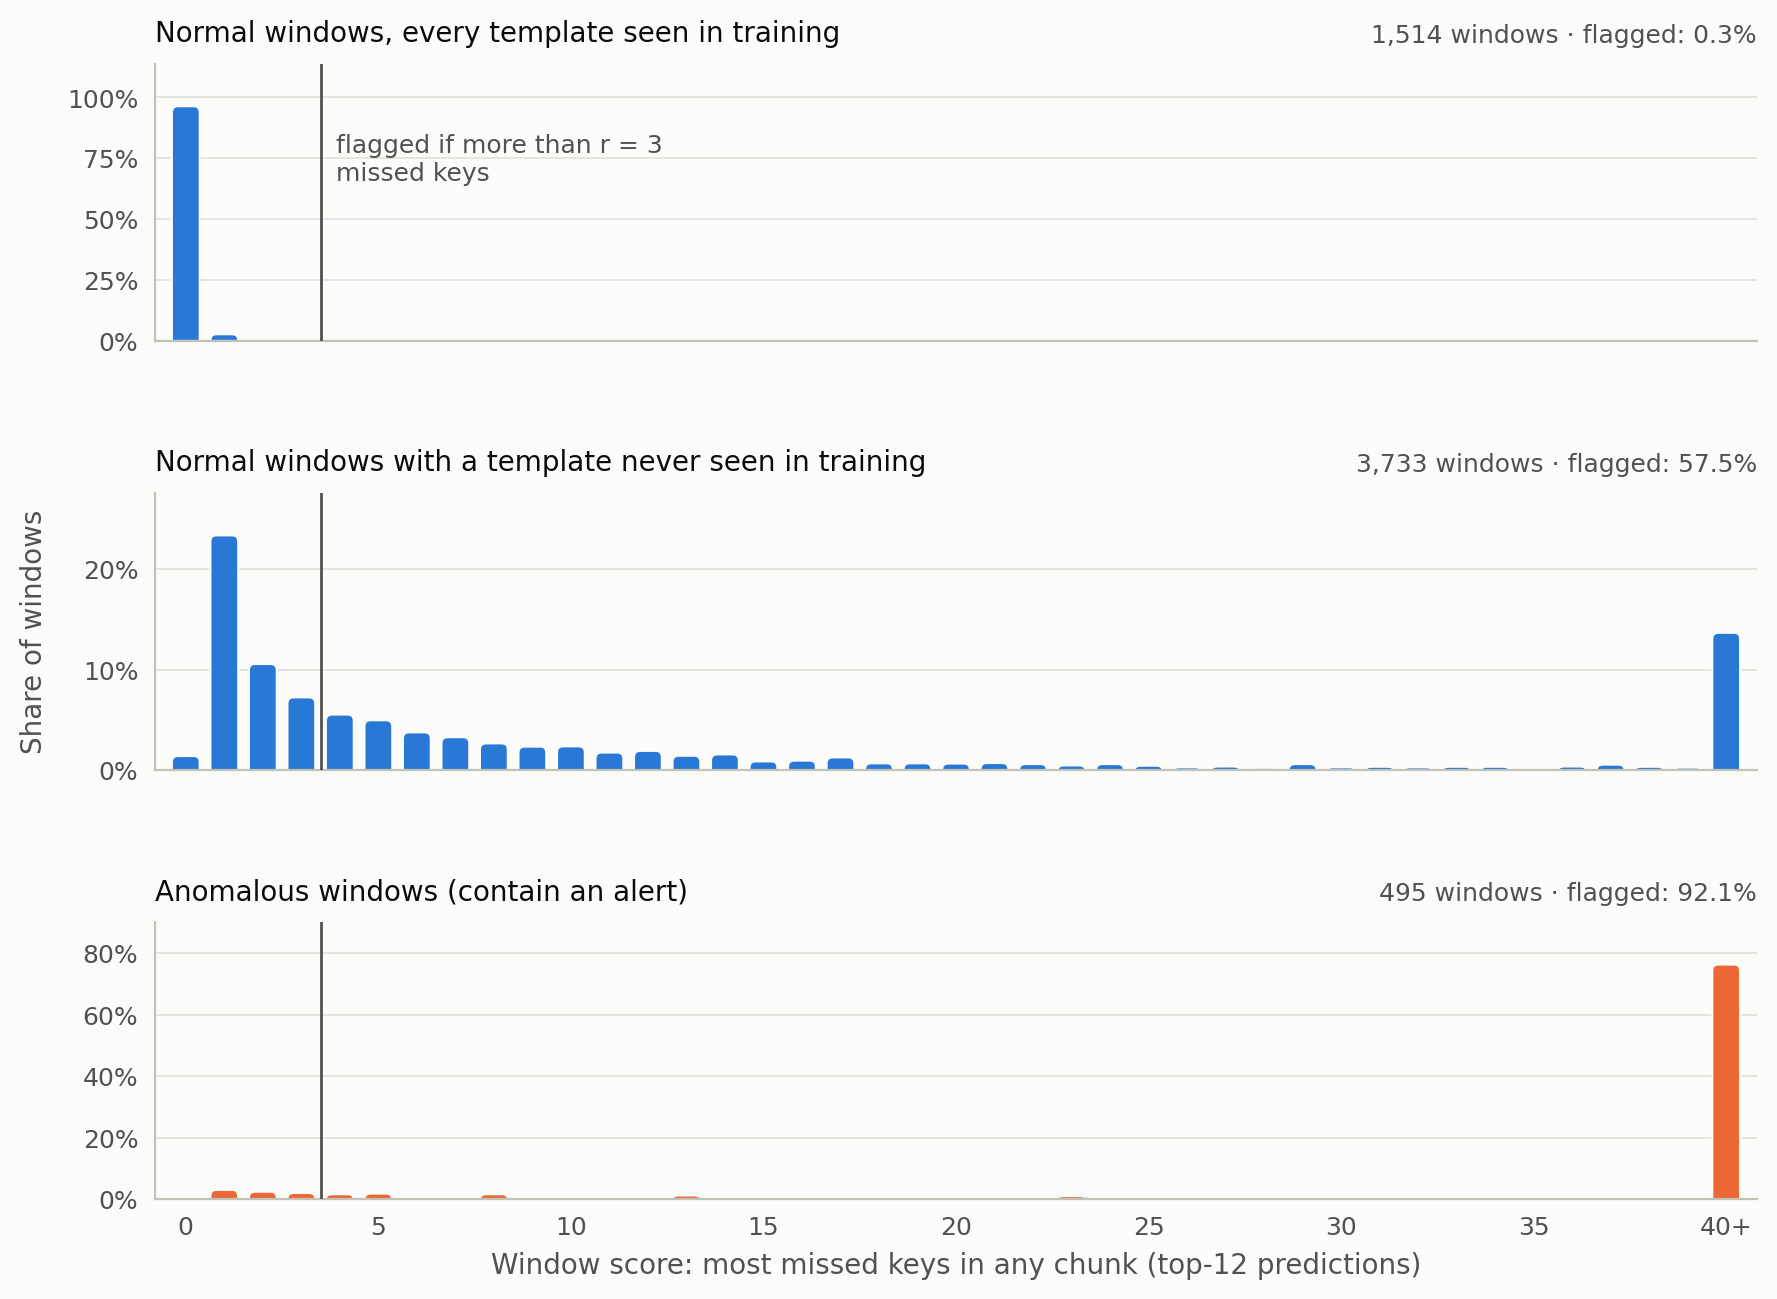

**Figure 7. Every method in precision-recall space**

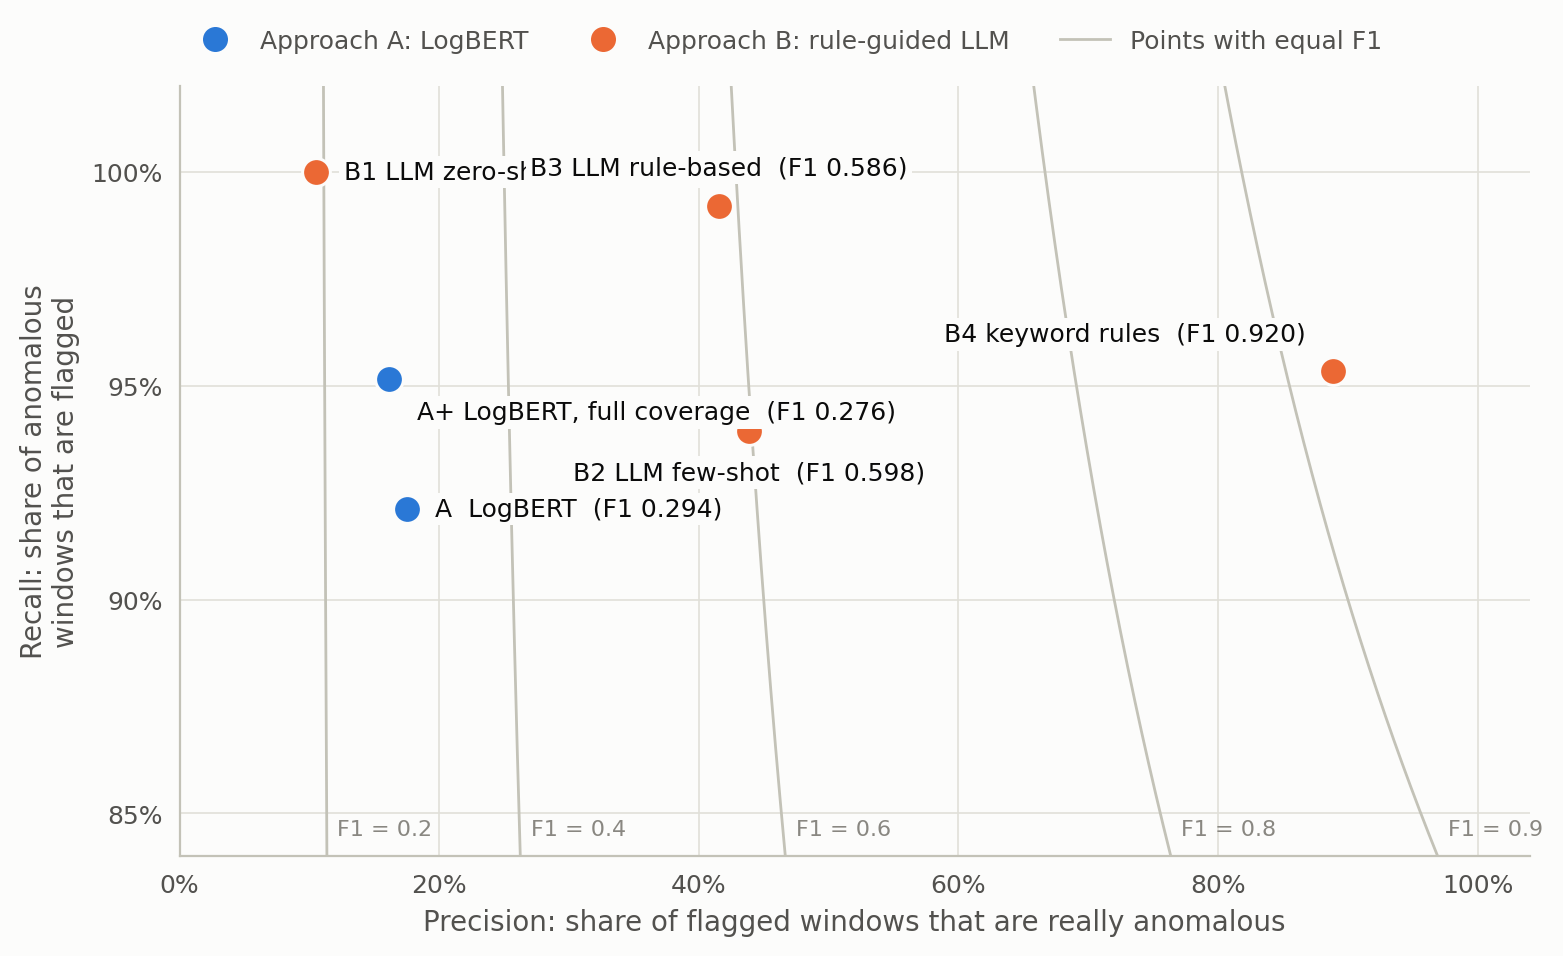

**Figure 8. Templates flagged by each approach B condition**

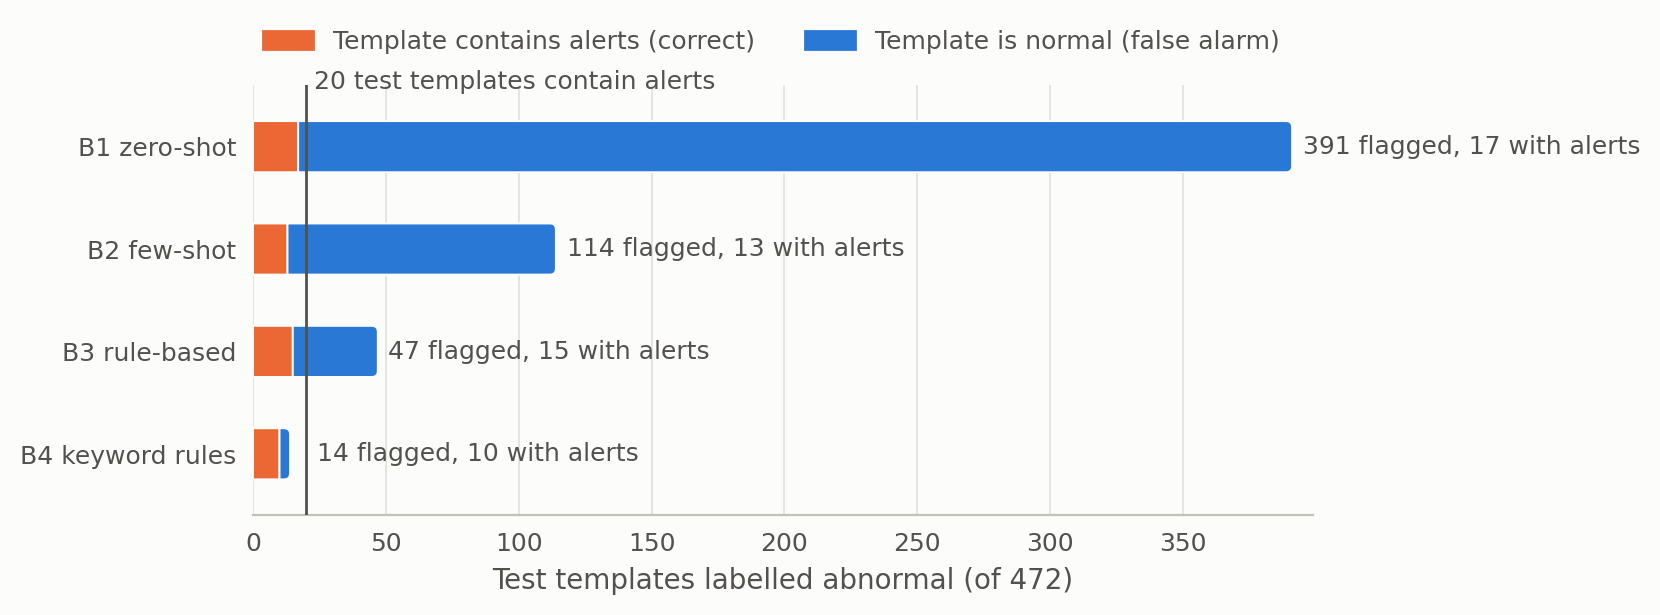

**Figure 9. Keyword rules: how many rules are needed**

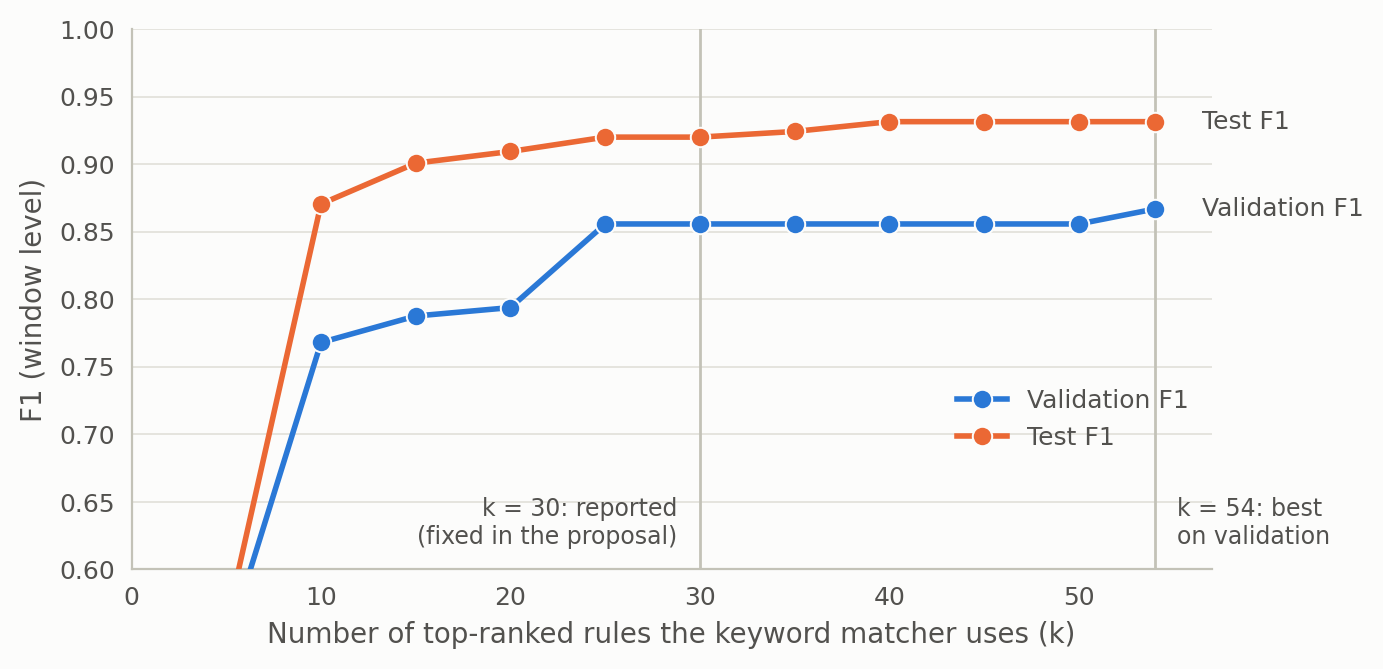

**Figure 10. What each method costs at inference time**

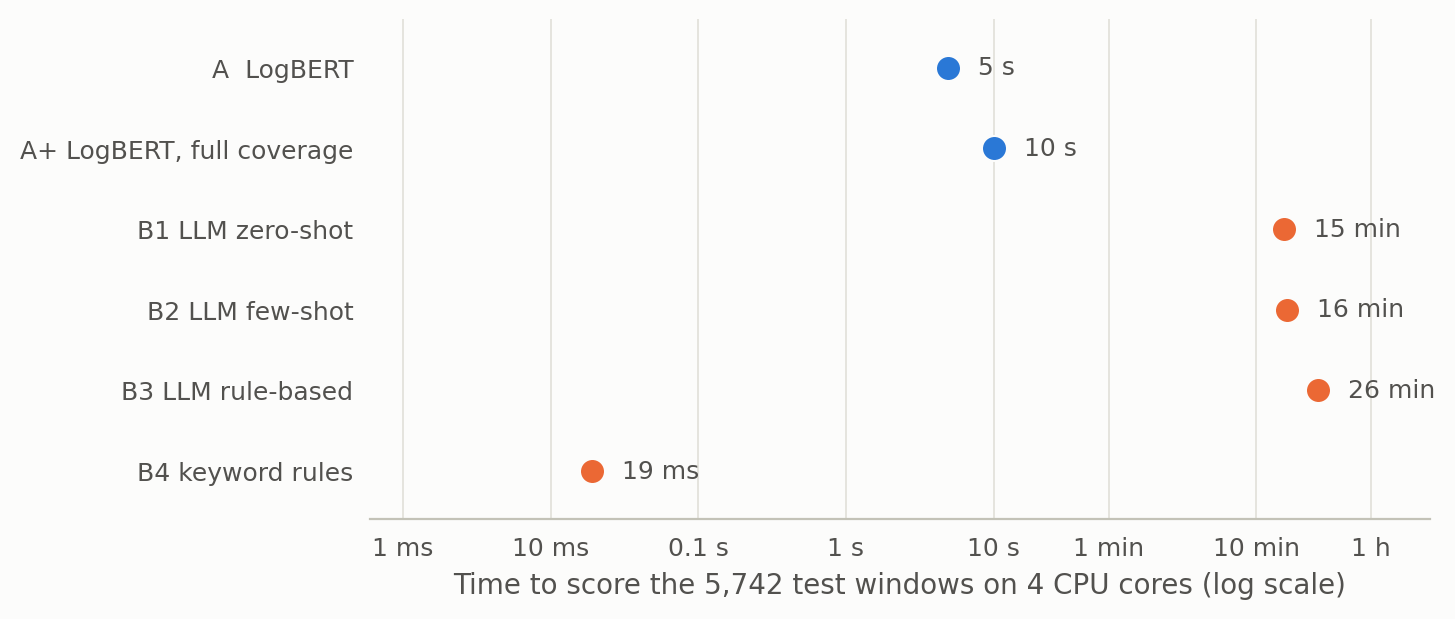

10 of 10 figures shown (from results_gpu/figures)


In [ ]:
GALLERY = {
    1: ("01_bgl_timeline.png", "Figure 1. BGL over time: normal and alert messages per week"),
    2: ("02_unseen_templates.png", "Figure 2. Share of messages whose template never occurred in the training period"),
    3: ("03_logbert_training.png", "Figure 3. LogBERT: loss per epoch"),
    4: ("04_logbert_tuning_grid.png", "Figure 4. LogBERT: validation F1 for every (g, r) setting"),
    5: ("05_logbert_key_misses.png", "Figure 5. LogBERT: which log keys it cannot predict (known templates against never-seen ones)"),
    6: ("06_logbert_window_scores.png", "Figure 6. LogBERT: window scores of normal, unseen-template and anomalous windows"),
    7: ("07_results_pr_space.png", "Figure 7. Every method in precision-recall space"),
    8: ("08_llm_flagged_templates.png", "Figure 8. Templates flagged by each approach B condition"),
    9: ("09_keyword_rule_sensitivity.png", "Figure 9. Keyword rules: how many rules are needed"),
    10: ("10_inference_cost.png", "Figure 10. What each method costs at inference time"),
}


def show_figures(*numbers):
    """Show figures of the run (all ten when no number is given)."""
    shown = 0
    for number in (numbers or sorted(GALLERY)):
        name, caption = GALLERY[number]
        if (FIG / name).exists():
            display(Markdown(f"**{caption}**"))
            display(Image(filename=str(FIG / name)))
            shown += 1
    print(f"{shown} of {len(numbers) or len(GALLERY)} figures shown (from {Path(FIG).parent.name}/{Path(FIG).name})")

show_figures()

In [ ]:
import json as _json
import platform

info = {
    "finished": time.strftime("%Y-%m-%d %H:%M"),
    "config": CONFIG,
    "smoke_test": SMOKE,
    "gpu": GPU_NAME,
    "torch": torch.__version__,
    "python": platform.python_version(),
    "approach_b": "run again on this GPU with " + LLM_MODEL + " (4-bit)" if RERUN_LLM else "reused from the reported run (results/)",
    "minutes_in_this_session": {name: round(seconds / 60, 1) for name, seconds in TIMES.items()},
}
(RES / "run_info.json").write_text(_json.dumps(info, indent=2) + "\n")
print(_json.dumps(info, indent=2))

shutil.make_archive("nlp-gpu-results", "zip", root_dir=".", base_dir=str(RES))
drive_push("outputs")
if DRIVE:
    shutil.copy("nlp-gpu-results.zip", DRIVE / "nlp-gpu-results.zip")
    print("copy in Drive:", DRIVE / "nlp-gpu-results.zip")
try:
    from google.colab import files
    files.download("nlp-gpu-results.zip")
except ImportError:
    print("saved:", Path("nlp-gpu-results.zip").resolve())

{
  "finished": "2026-11-14 14:12",
  "config": "configs/bgl_gpu.yaml",
  "smoke_test": false,
  "gpu": "Tesla T4",
  "torch": "2.14.1+cu130",
  "python": "3.13.16",
  "approach_b": "run again on this GPU with Qwen/Qwen2.5-7B-Instruct (4-bit)",
  "minutes_in_this_session": {
    "classify": 14.8,
    "compare": 0.0,
    "analyze": 0.5,
    "figures": 2.0
  }
}
saved to Drive: outputs
copy in Drive: /content/drive/MyDrive/CA-NLP-run/nlp-gpu-results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. What to do with the results

1. The download `nlp-gpu-results.zip` holds the folder `results_gpu/`. Unzip it **inside the folder `NLP` of your project** (next to `results/`).
2. Save this notebook with its outputs: *File ▸ Download ▸ Download .ipynb*, and put the file in `NLP/notebooks/` as `train_on_gpu_run.ipynb`.
3. Commit both. `results/` (the reported CPU run) stays untouched, so both runs are in the repository.

```bash
cd ~/Desktop/CA/NLP && unzip -o ~/Downloads/nlp-gpu-results.zip
cd ~/Desktop/CA && git add NLP/results_gpu NLP/notebooks && git commit -m "Add the GPU run (full LogBERT recipe, approach B rerun)" && git push
```